In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find the downloaded project folder
PROJECT_ROOT = Path.home() / "Downloads" / "DATA7703-Group-Project-main"

print("Project folder:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())
print("Data folder exists:", (PROJECT_ROOT / "data").exists())
print("Source folder exists:", (PROJECT_ROOT / "src").exists())

/Users/shashankbabu/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/shashankbabu/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Project folder: /Users/shashankbabu/Downloads/DATA7703-Group-Project-main
Project exists: True
Data folder exists: True
Source folder exists: True


In [2]:
# Load the existing frozen patient split
split_path = PROJECT_ROOT / "data" / "splits" / "patient_split.csv"

df = pd.read_csv(split_path)

print("Total images:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Total images: 27558

Column names:
['filename', 'patient_id', 'category', 'split']

First five records:


,filename,patient_id,category,split
0,C118P79ThinF_IMG_20151002_105018_cell_150.png,C118P79ThinF,Parasitized,train
1,C189P150ThinF_IMG_20151203_142224_cell_84.png,C189P150ThinF,Parasitized,train
2,C91P52ThinF_IMG_20150821_123116_cell_189.png,C91P52ThinF,Parasitized,train
3,C84P45ThinF_IMG_20150818_101226_cell_98.png,C84P45ThinF,Parasitized,train
4,C144P105ThinF_IMG_20151015_163432_cell_310.png,C144P105ThinF,Parasitized,train


In [3]:
# Check whether any patient appears in multiple splits
patient_split_counts = df.groupby("patient_id")["split"].nunique()

leaking_patients = patient_split_counts[
    patient_split_counts > 1
]

print("Total unique patients:", df["patient_id"].nunique())
print("Patients appearing in multiple splits:", len(leaking_patients))

if len(leaking_patients) == 0:
    print("PASS: No patient overlap detected!")
else:
    print("WARNING: Patient-level leakage detected!")
    display(leaking_patients)

Total unique patients: 201
Patients appearing in multiple splits: 0
PASS: No patient overlap detected!


In [4]:
# Count images in each split and category
class_distribution = pd.crosstab(
    df["split"],
    df["category"]
)

# Add total images for each split
class_distribution["Total"] = class_distribution.sum(axis=1)

# Calculate percentage of the whole dataset
class_distribution["Percentage (%)"] = (
    class_distribution["Total"] / len(df) * 100
).round(2)

print("Class Distribution Across Splits:")
display(class_distribution)

# Count unique patients in each split
print("\nUnique Patients Per Split:")
display(df.groupby("split")["patient_id"].nunique())

Class Distribution Across Splits:


category,Parasitized,Uninfected,Total,Percentage (%)
split,,,,
test,1967,2143,4110,14.91
train,9548,9576,19124,69.40
val,2264,2060,4324,15.69



Unique Patients Per Split:


split
test      31
train    140
val       30
Name: patient_id, dtype: int64

In [5]:
from PIL import Image
import numpy as np

def load_and_pad(path: str, size: int = 128) -> np.ndarray:
    """
    Load and preprocess a red blood cell image.

    Parameters
    ----------
    path : str
        Path to the input image.
    size : int
        Desired square image size, e.g. 32 or 128.

    Returns
    -------
    np.ndarray
        RGB image of shape (size, size, 3).
        dtype: float32
        Pixel range: [0, 1].
    """

    if not isinstance(size, (int, np.integer)) or size <= 0:
        raise ValueError("size must be a positive integer")

    with Image.open(path) as source:
        img = source.convert("RGB")

    width, height = img.size

    scale = size / max(width, height)
    new_width = max(1, int(round(width * scale)))
    new_height = max(1, int(round(height * scale)))

    img = img.resize(
        (new_width, new_height),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new(
        "RGB",
        (size, size),
        (0, 0, 0)
    )

    x = (size - new_width) // 2
    y = (size - new_height) // 2

    canvas.paste(img, (x, y))

    return np.asarray(canvas, dtype=np.float32) / 255.0


print("Preprocessing function defined successfully!")

Preprocessing function defined successfully!


In [6]:
image_root = PROJECT_ROOT / "data" / "raw" / "cell_images"

print("Dataset folder exists:", image_root.exists())
print("Parasitized folder exists:", (image_root / "Parasitized").exists())
print("Uninfected folder exists:", (image_root / "Uninfected").exists())

Dataset folder exists: True
Parasitized folder exists: True
Uninfected folder exists: True


In [7]:
# Check that every image in the frozen split exists
from pathlib import Path

df["image_path"] = df.apply(
    lambda row: image_root / row["category"] / row["filename"],
    axis=1
)

df["file_exists"] = df["image_path"].apply(
    lambda path: path.is_file()
)

total_images = len(df)
found_images = int(df["file_exists"].sum())
missing_images = total_images - found_images

print("Expected images:", total_images)
print("Images found:", found_images)
print("Missing images:", missing_images)

if missing_images == 0:
    print("\nPASS: All frozen-split images are present!")
else:
    print("\nWARNING: Some images are missing.")
    display(
        df.loc[
            ~df["file_exists"],
            ["filename", "category", "split"]
        ].head(10)
    )

Expected images: 27558
Images found: 27558
Missing images: 0

PASS: All frozen-split images are present!


Original image: C118P79ThinF_IMG_20151002_105018_cell_150.png
Category: Parasitized

32x32 result:
Shape: (32, 32, 3)
Data type: float32
Pixel range: 0.0 0.8627451

128x128 result:
Shape: (128, 128, 3)
Data type: float32
Pixel range: 0.0 0.8745098


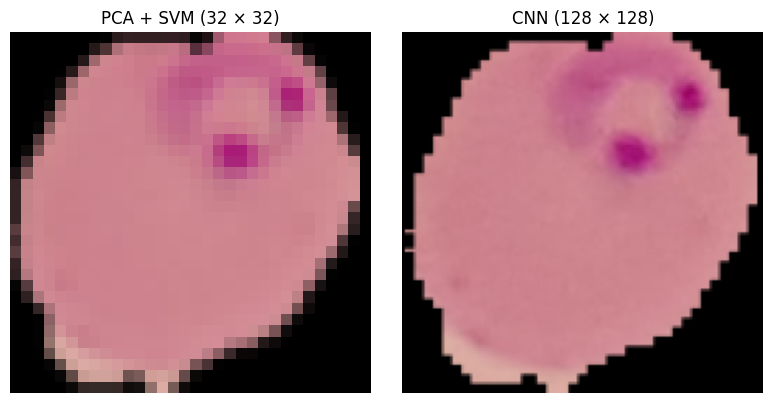

In [8]:
import matplotlib.pyplot as plt

# Select an existing image from the frozen split
sample = df.iloc[0]
image_path = sample["image_path"]

# Apply our preprocessing function
img_32 = load_and_pad(str(image_path), size=32)
img_128 = load_and_pad(str(image_path), size=128)

# Check dimensions and pixel values
print("Original image:", sample["filename"])
print("Category:", sample["category"])

print("\n32x32 result:")
print("Shape:", img_32.shape)
print("Data type:", img_32.dtype)
print("Pixel range:", img_32.min(), img_32.max())

print("\n128x128 result:")
print("Shape:", img_128.shape)
print("Data type:", img_128.dtype)
print("Pixel range:", img_128.min(), img_128.max())

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(img_32)
axes[0].set_title("PCA + SVM (32 × 32)")
axes[0].axis("off")

axes[1].imshow(img_128)
axes[1].set_title("CNN (128 × 128)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
def normalize_image(image: np.ndarray, method: str = "zero_one") -> np.ndarray:
    """
    Apply configurable pixel normalisation.

    Parameters
    ----------
    image : np.ndarray
        RGB image with float32 values in [0, 1],
        produced by load_and_pad().

    method : str
        "zero_one"  - keep pixel values in [0, 1]
        "imagenet"  - apply ImageNet mean/std normalisation
        "none"      - return raw pixel values in [0, 255]

    Returns
    -------
    np.ndarray
        Normalised RGB image with shape (H, W, 3).
    """

    image = np.asarray(image, dtype=np.float32)

    if method == "zero_one":
        return image.copy()

    elif method == "imagenet":
        mean = np.array(
            [0.485, 0.456, 0.406], dtype=np.float32
        )
        std = np.array(
            [0.229, 0.224, 0.225], dtype=np.float32
        )

        return (image - mean) / std

    elif method == "none":
        return image * 255.0

    else:
        raise ValueError(
            "method must be 'zero_one', 'imagenet', or 'none'"
        )


print("Configurable normalisation function defined!")

Configurable normalisation function defined!


In [10]:
# Test the three normalisation methods
img_zero_one = normalize_image(img_128, "zero_one")
img_imagenet = normalize_image(img_128, "imagenet")
img_none = normalize_image(img_128, "none")

print("NORMALISATION TEST RESULTS\n")

for name, image in [
    ("Zero-One", img_zero_one),
    ("ImageNet", img_imagenet),
    ("None", img_none)
]:
    print(f"{name}:")
    print(" Shape:", image.shape)
    print(" Data type:", image.dtype)
    print(" Minimum:", round(float(image.min()), 4))
    print(" Maximum:", round(float(image.max()), 4))
    print()

# Confirm all normalisation methods retain image dimensions
assert img_zero_one.shape == (128, 128, 3)
assert img_imagenet.shape == (128, 128, 3)
assert img_none.shape == (128, 128, 3)

# Confirm the 0–1 scaling is correct
assert img_zero_one.min() >= 0
assert img_zero_one.max() <= 1

# Confirm raw-range conversion
assert np.allclose(img_none, img_128 * 255)

# Confirm ImageNet normalisation
imagenet_mean = np.array([0.485, 0.456, 0.406])
imagenet_std = np.array([0.229, 0.224, 0.225])

expected = (img_128 - imagenet_mean) / imagenet_std

assert np.allclose(img_imagenet, expected, atol=1e-6)

print("PASS: All normalisation tests passed!")

NORMALISATION TEST RESULTS

Zero-One:
 Shape: (128, 128, 3)
 Data type: float32
 Minimum: 0.0
 Maximum: 0.8745

ImageNet:
 Shape: (128, 128, 3)
 Data type: float32
 Minimum: -2.1179
 Maximum: 1.7009

None:
 Shape: (128, 128, 3)
 Data type: float32
 Minimum: 0.0
 Maximum: 223.0

PASS: All normalisation tests passed!


In [11]:
from PIL import Image
import numpy as np

# Original temporary function from the CNN notebook
def original_cnn_loader(path, size=128):
    img = Image.open(path).convert("RGB")
    w, h = img.size

    scale = size / max(w, h)
    new_w = int(round(w * scale))
    new_h = int(round(h * scale))

    img = img.resize((new_w, new_h), Image.BILINEAR)

    canvas = Image.new("RGB", (size, size), (0, 0, 0))

    paste_x = (size - new_w) // 2
    paste_y = (size - new_h) // 2

    canvas.paste(img, (paste_x, paste_y))

    return np.asarray(canvas, dtype=np.float32) / 255.0


# Compare both functions using 10 real images
sample_paths = df["image_path"].head(10)

differences = []

for path in sample_paths:
    original = original_cnn_loader(str(path), 128)
    new = load_and_pad(str(path), 128)

    difference = np.max(np.abs(original - new))
    differences.append(difference)

print("Images compared:", len(differences))
print("Maximum pixel difference:", max(differences))

assert all(d == 0 for d in differences)

print("PASS: Shared preprocessing matches original CNN loader!")

Images compared: 10
Maximum pixel difference: 0.0
PASS: Shared preprocessing matches original CNN loader!


/var/folders/hb/gkpttpss63s6v0w3ff8zlx8m0000gn/T/ipykernel_61541/3347584712.py:13: DeprecationWarning: BILINEAR is deprecated and will be removed in Pillow 10 (2023-07-01). Use Resampling.BILINEAR instead.
  img = img.resize((new_w, new_h), Image.BILINEAR)


In [12]:
shared_code = '''
"""Shared image preprocessing for DATA7703 malaria classification."""

import numpy as np
from PIL import Image


def load_and_pad(path: str, size: int = 128) -> np.ndarray:
    """
    Load an RGB image, resize with preserved aspect ratio,
    and centre it on a black square canvas.

    Parameters
    ----------
    path : str
        Path to the source image.
    size : int
        Target width and height in pixels.

    Returns
    -------
    np.ndarray
        Float32 RGB array with shape (size, size, 3)
        and pixel values in [0, 1].
    """
    if not isinstance(size, (int, np.integer)) or size <= 0:
        raise ValueError("size must be a positive integer")

    with Image.open(path) as source:
        img = source.convert("RGB")

    width, height = img.size
    scale = size / max(width, height)

    new_width = max(1, int(round(width * scale)))
    new_height = max(1, int(round(height * scale)))

    img = img.resize(
        (new_width, new_height),
        Image.Resampling.BILINEAR
    )

    canvas = Image.new("RGB", (size, size), (0, 0, 0))

    x = (size - new_width) // 2
    y = (size - new_height) // 2

    canvas.paste(img, (x, y))

    return np.asarray(canvas, dtype=np.float32) / 255.0


def normalize_image(image: np.ndarray, method: str = "zero_one") -> np.ndarray:
    """
    Normalise an RGB image produced by load_and_pad().

    Parameters
    ----------
    image : np.ndarray
        Float32 RGB array with values in [0, 1].
    method : str
        "zero_one": preserve [0, 1] scaling.
        "imagenet": apply ImageNet channel mean/std.
        "none": return the 0-255 numeric range.

    Returns
    -------
    np.ndarray
        Float32 RGB array with unchanged dimensions.
    """
    image = np.asarray(image, dtype=np.float32)

    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Expected an RGB image with shape (H, W, 3)")

    if not np.isfinite(image).all() or image.min() < 0 or image.max() > 1:
        raise ValueError("Input pixel values must be finite and within [0, 1]")

    if method == "zero_one":
        return image.copy()

    if method == "imagenet":
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
        return (image - mean) / std

    if method == "none":
        return image * 255.0

    raise ValueError("Unknown normalisation method")


def scale_pixels(images: np.ndarray) -> np.ndarray:
    """
    Scale raw image arrays from [0, 255] to [0, 1].

    Use this for raw pixel arrays, not arrays already
    returned by load_and_pad().
    """
    images = np.asarray(images, dtype=np.float32)

    if not np.isfinite(images).all() or images.min() < 0 or images.max() > 255:
        raise ValueError("Expected finite pixel values in [0, 255]")

    return images / 255.0
'''

# Save to the existing project module
preprocessing_path = PROJECT_ROOT / "src" / "preprocessing.py"
preprocessing_path.write_text(shared_code, encoding="utf-8")

print("Saved:", preprocessing_path)
print("File size:", preprocessing_path.stat().st_size, "bytes")

Saved: /Users/shashankbabu/Downloads/DATA7703-Group-Project-main/src/preprocessing.py
File size: 2866 bytes


In [13]:
import sys
import numpy as np

# Make the project's src folder importable
src_path = str(PROJECT_ROOT / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import the actual shared preprocessing functions
from preprocessing import load_and_pad, normalize_image, scale_pixels

# Test using a real malaria image
test_image = str(df.iloc[0]["image_path"])

cnn_image = load_and_pad(test_image, size=128)
svm_image = load_and_pad(test_image, size=32)
resnet_image = normalize_image(cnn_image, method="imagenet")

# Validate outputs
assert cnn_image.shape == (128, 128, 3)
assert svm_image.shape == (32, 32, 3)
assert resnet_image.shape == (128, 128, 3)

assert np.isfinite(cnn_image).all()
assert np.isfinite(svm_image).all()
assert np.isfinite(resnet_image).all()

# Test the separate raw-pixel scaling function
raw_pixels = np.array([0, 127.5, 255], dtype=np.float32)
scaled = scale_pixels(raw_pixels)

assert np.allclose(scaled, [0, 0.5, 1])

print("PASS: All functions imported successfully!")
print("CNN shape:", cnn_image.shape)
print("SVM shape:", svm_image.shape)
print("ResNet shape:", resnet_image.shape)
print("PASS: Shared preprocessing module works!")

PASS: All functions imported successfully!
CNN shape: (128, 128, 3)
SVM shape: (32, 32, 3)
ResNet shape: (128, 128, 3)
PASS: Shared preprocessing module works!



## Shared Image Preprocessing : Input and Output Documentation

### Purpose
This module provides consistent, configurable image preprocessing for the PCA + SVM, small CNN and ResNet-18 models. All models use the same frozen patient-level split, while image size and normalisation can be selected independently.

### Input
- Image path: Path to a malaria-cell image.
- Image size: Positive integer specifying square output dimensions.
- Normalisation method: `zero_one`, `imagenet`, or `none`.

### Processing
1. Load the image and convert it to RGB.
2. Resize using bilinear interpolation while preserving aspect ratio.
3. Centre the resized image on a black square canvas.
4. Convert to a float32 NumPy array scaled to [0, 1].
5. Optionally apply the selected normalisation method.

### Output
- Array shape: `(size, size, 3)`
- Data type: `float32`
- Channel order: RGB (height, width, channels)
- Pixel range:
  - `zero_one`: [0, 1]
  - `imagenet`: ImageNet mean/std standardisation
  - `none`: [0, 255]

### Model Configurations

| Model | Image Size | Normalisation |
|---|---|---|
| PCA + Linear SVM | 32 × 32 | zero_one |
| Small CNN | 128 × 128 | zero_one |
| ResNet-18 | 128 × 128 | imagenet |

### Reproducibility and Leakage Prevention
- All models use the existing frozen `patient_split.csv`.
- The manifest contains 27,558 images and 201 recorded patient IDs.
- No recorded patient ID appears in multiple splits.
- No new train/validation/test split is generated during preprocessing.
- PCA and other fitted transformations must be fitted on training data only.
- ImageNet normalisation must not be applied twice.

### Validation Completed
- Verified that all 27,558 manifest image paths exist.
- Confirmed patient-ID separation across splits.
- Tested 32 × 32 and 128 × 128 outputs.
- Verified three normalisation options.
- Matched the existing CNN loader on 10 sample images with zero pixel difference.

### Remaining Checks
- Audit unreadable images and duplicate image content.
- Review possible patient identifier aliases.
- Confirm integration with the model notebooks.


In [14]:
from PIL import Image
from tqdm.auto import tqdm

corrupted_images = []
image_formats = {}

for path in tqdm(df["image_path"], desc="Checking images"):
    try:
        with Image.open(path) as img:
            img.verify()
            image_format = img.format

        image_formats[image_format] = (
            image_formats.get(image_format, 0) + 1
        )

    except Exception as e:
        corrupted_images.append({
            "filename": path.name,
            "error": str(e)
        })

print("\nTotal images checked:", len(df))
print("Unreadable images:", len(corrupted_images))
print("Image formats:", image_formats)

if len(corrupted_images) == 0:
    print("\nPASS: All images passed the readability check!")
else:
    print("\nWARNING: Unreadable images detected!")
    display(pd.DataFrame(corrupted_images))

Checking images:   0%|          | 0/27558 [00:00<?, ?it/s]


Total images checked: 27558
Unreadable images: 0
Image formats: {'PNG': 27558}

PASS: All images passed the readability check!


In [15]:
import hashlib
from tqdm.auto import tqdm

def calculate_sha256(path):
    """Calculate SHA-256 hash of an image file."""
    hasher = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


# Calculate hashes for all images
df["sha256"] = [
    calculate_sha256(path)
    for path in tqdm(df["image_path"], desc="Hashing images")
]

# Identify duplicate image contents
duplicates = df[df.duplicated("sha256", keep=False)].copy()

# Check whether identical content crosses data splits
hash_split_counts = df.groupby("sha256")["split"].nunique()

cross_split_duplicates = hash_split_counts[
    hash_split_counts > 1
]

print("Total images:", len(df))
print("Unique image hashes:", df["sha256"].nunique())
print("Images involved in duplicate groups:", len(duplicates))
print("Duplicate hash groups:", duplicates["sha256"].nunique())
print("Duplicate hash groups across splits:", len(cross_split_duplicates))

if len(cross_split_duplicates) == 0:
    print("\nPASS: No byte-identical images across splits!")
else:
    print("\nWARNING: Cross-split duplicate content detected!")
    display(
        df[df["sha256"].isin(cross_split_duplicates.index)]
        [["filename", "patient_id", "category", "split", "sha256"]]
        .sort_values("sha256")
    )

Hashing images:   0%|          | 0/27558 [00:00<?, ?it/s]

Total images: 27558
Unique image hashes: 27558
Images involved in duplicate groups: 0
Duplicate hash groups: 0
Duplicate hash groups across splits: 0

PASS: No byte-identical images across splits!


In [16]:
# Check patient identifiers and their class associations

patient_classes = (
    df.groupby("patient_id")["category"]
    .nunique()
)

multi_class_patients = patient_classes[
    patient_classes > 1
]

print("Unique patient IDs:", df["patient_id"].nunique())
print("Missing patient IDs:", df["patient_id"].isna().sum())
print("Patients associated with both classes:",
      len(multi_class_patients))

print("\nPatient ID examples:")
print(df["patient_id"].drop_duplicates().head(15).tolist())

print("\nImages per patient summary:")
display(
    df.groupby("patient_id")
    .size()
    .describe()
)

if len(multi_class_patients) > 0:
    print("\nPatients associated with both classes:")
    display(multi_class_patients.head(20))

Unique patient IDs: 201
Missing patient IDs: 0
Patients associated with both classes: 151

Patient ID examples:
['C118P79ThinF', 'C189P150ThinF', 'C91P52ThinF', 'C84P45ThinF', 'C144P105ThinF', 'C136P97ThinF', 'C60P21thinF', 'C109P70ThinF', 'C176P137NThinF', 'C173P134NThinF', 'C85P46ThinF', 'C132P93ThinF', 'C116P77ThinF', 'C184P145ThinF', 'C175P136NThinF']

Images per patient summary:


count    201.000000
mean     137.104478
std      126.789448
min       65.000000
25%       70.000000
50%       85.000000
75%      130.000000
max      702.000000
dtype: float64


Patients associated with both classes:


patient_id
C100P61ThinF    2
C101P62ThinF    2
C102P63ThinF    2
C103P64ThinF    2
C104P65ThinF    2
C105P66ThinF    2
C106P67ThinF    2
C107P68ThinF    2
C108P69ThinF    2
C109P70ThinF    2
C110P71ThinF    2
C111P72ThinF    2
C112P73ThinF    2
C113P74ThinF    2
C114P75ThinF    2
C115P76ThinF    2
C116P77ThinF    2
C117P78ThinF    2
C118P79ThinF    2
C119P80ThinF    2
Name: category, dtype: int64

In [17]:
# Investigate possible patient-ID formatting inconsistencies

patient_ids = (
    df["patient_id"]
    .dropna()
    .astype(str)
    .drop_duplicates()
)

# Check for IDs that differ only in letter case
case_groups = {}

for patient_id in patient_ids:
    key = patient_id.lower()
    case_groups.setdefault(key, []).append(patient_id)

case_aliases = {
    key: values
    for key, values in case_groups.items()
    if len(values) > 1
}

print("Unique recorded patient IDs:", len(patient_ids))
print("Case-only identifier collisions:", len(case_aliases))

if case_aliases:
    for key, values in case_aliases.items():
        print(values)
else:
    print("PASS: No case-only identifier collisions detected.")

# Show identifier suffix patterns for review
suffix_counts = {
    "NThinF": patient_ids.str.contains(
        "NThinF", case=False, regex=False
    ).sum(),
    "ThinF without N": (
        patient_ids.str.contains("ThinF", case=False, regex=False)
        & ~patient_ids.str.contains(
            "NThinF", case=False, regex=False
        )
    ).sum()
}

print("\nIdentifier patterns:")
print(suffix_counts)

Unique recorded patient IDs: 201
Case-only identifier collisions: 0
PASS: No case-only identifier collisions detected.

Identifier patterns:
{'NThinF': 19, 'ThinF without N': 177}


In [18]:
# Identify patient IDs that do not match either suffix pattern

matches_known_pattern = (
    patient_ids.str.contains(
        "ThinF", case=False, regex=False
    )
)

unusual_ids = patient_ids[~matches_known_pattern]

print("Patient IDs with other naming patterns:")
print(unusual_ids.tolist())

print("\nNumber of unusual IDs:", len(unusual_ids))

# Check which split contains their images
if len(unusual_ids) > 0:
    display(
        df[df["patient_id"].isin(unusual_ids)]
        .groupby(["patient_id", "split"])
        .size()
        .reset_index(name="image_count")
    )

Patient IDs with other naming patterns:
['C42P5thin_original', 'C47P8thin_Original_Motic', 'C47P8thinOriginalOlympusCX21', 'C4thin_original', 'C3thin_original']

Number of unusual IDs: 5


,patient_id,split,image_count
0,C3thin_original,train,69
1,C42P5thin_original,train,76
2,C47P8thinOriginalOlympusCX21,train,67
3,C47P8thin_Original_Motic,train,77
4,C4thin_original,train,67


In [19]:
import re

# Extract the common C-number/P-number prefix where available
def extract_patient_prefix(patient_id):
    match = re.match(
        r"^(C\d+P\d+)",
        str(patient_id),
        flags=re.IGNORECASE
    )
    return match.group(1).upper() if match else None


prefix_df = pd.DataFrame({
    "patient_id": patient_ids.tolist()
})

prefix_df["prefix"] = prefix_df["patient_id"].apply(
    extract_patient_prefix
)

# Find prefixes shared by different identifiers
alias_candidates = (
    prefix_df.dropna(subset=["prefix"])
    .groupby("prefix")["patient_id"]
    .agg(list)
)

alias_candidates = alias_candidates[
    alias_candidates.apply(len) > 1
]

print("Potential shared-prefix groups:", len(alias_candidates))

for prefix, ids in alias_candidates.items():
    print(f"\n{prefix}: {ids}")

    affected = df[df["patient_id"].isin(ids)]

    print(
        "Splits involved:",
        affected["split"].unique().tolist()
    )

    print(
        "Total images:",
        len(affected)
    )

Potential shared-prefix groups: 1

C47P8: ['C47P8thin_Original_Motic', 'C47P8thinOriginalOlympusCX21']
Splits involved: ['train']
Total images: 144


In [20]:
# Reload mapping files without treating the first row as headers

parasitized_mapping = pd.read_csv(
    PROJECT_ROOT / "data/raw/patientid_cellmapping_parasitized.csv",
    header=None
)

uninfected_mapping = pd.read_csv(
    PROJECT_ROOT / "data/raw/patientid_cellmapping_uninfected.csv",
    header=None
)

print("PARASITIZED")
print("Rows:", len(parasitized_mapping))
print("First patient:", parasitized_mapping.iloc[0, 0])
print("First 3 image entries:",
      parasitized_mapping.iloc[0, 1:4].tolist())

print("\nUNINFECTED")
print("Rows:", len(uninfected_mapping))
print("First patient:", uninfected_mapping.iloc[0, 0])
print("First 3 image entries:",
      uninfected_mapping.iloc[0, 1:4].tolist())

PARASITIZED
Rows: 151
First patient: C100P61ThinF
First 3 image entries: ["['C100P61ThinF_IMG_20150918_144104_cell_162.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_163.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_164.png'"]

UNINFECTED
Rows: 201
First patient: C100P61ThinF
First 3 image entries: ["['C100P61ThinF_IMG_20150918_144104_cell_128.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_131.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_144.png'"]


In [21]:
import re
import pandas as pd

def extract_mapping(mapping, category):
    records = []

    for row in mapping.itertuples(index=False, name=None):
        patient_id = str(row[0]).strip()

        for entry in row[1:]:
            if pd.isna(entry):
                continue

            # Extract image filenames from list-like CSV entries
            filenames = re.findall(
                r"[A-Za-z0-9_.-]+\.png",
                str(entry),
                flags=re.IGNORECASE
            )

            for filename in filenames:
                records.append({
                    "filename": filename,
                    "patient_id_official": patient_id,
                    "category": category
                })

    return pd.DataFrame(records)


# Extract both official mappings
official_mapping = pd.concat(
    [
        extract_mapping(parasitized_mapping, "Parasitized"),
        extract_mapping(uninfected_mapping, "Uninfected")
    ],
    ignore_index=True
)

# Match using both filename and class
comparison = df.merge(
    official_mapping,
    on=["filename", "category"],
    how="left",
    validate="one_to_one",
    indicator=True
)

# Check the results
missing = comparison["_merge"].eq("left_only")
mismatched = (
    ~missing &
    comparison["patient_id"].ne(comparison["patient_id_official"])
)

print("Frozen split images:", len(df))
print("Official mapping entries:", len(official_mapping))
print("Images missing from official mapping:", missing.sum())
print("Patient ID mismatches:", mismatched.sum())

if missing.sum() == 0 and mismatched.sum() == 0:
    print("\nPASS: All frozen-split patient IDs match the official mappings!")
else:
    print("\nWARNING: Mapping inconsistencies detected.")
    display(
        comparison.loc[
            missing | mismatched,
            ["filename", "category", "patient_id",
             "patient_id_official"]
        ].head(10)
    )

Frozen split images: 27558
Official mapping entries: 27558
Images missing from official mapping: 0
Patient ID mismatches: 0

PASS: All frozen-split patient IDs match the official mappings!


In [22]:
# Prepare the final validation summary

validation_summary = pd.DataFrame({
    "Validation Check": [
        "Total images",
        "Unique recorded patient IDs",
        "Missing image files",
        "Unreadable image files",
        "Exact duplicate images",
        "Cross-split exact duplicate groups",
        "Patient IDs crossing splits",
        "Images missing from official mappings",
        "Official patient-ID mismatches",
        "Potential shared-prefix alias groups"
    ],
    "Result": [
        len(df),
        df["patient_id"].nunique(),
        (~df["file_exists"]).sum(),
        len(corrupted_images),
        len(df) - df["sha256"].nunique(),
        len(cross_split_duplicates),
        len(leaking_patients),
        int(missing.sum()),
        int(mismatched.sum()),
        len(alias_candidates)
    ]
})

display(validation_summary)

# Save the validation summary
output_path = PROJECT_ROOT / "data" / "splits" / "validation_summary.csv"

validation_summary.to_csv(output_path, index=False)

print("\nSaved validation summary to:")
print(output_path)

,Validation Check,Result
0,Total images,27558
1,Unique recorded patient IDs,201
2,Missing image files,0
3,Unreadable image files,0
4,Exact duplicate images,0
5,Cross-split exact duplicate groups,0
6,Patient IDs crossing splits,0
7,Images missing from official mappings,0
8,Official patient-ID mismatches,0
9,Potential shared-prefix alias groups,1



Saved validation summary to:
/Users/shashankbabu/Downloads/DATA7703-Group-Project-main/data/splits/validation_summary.csv


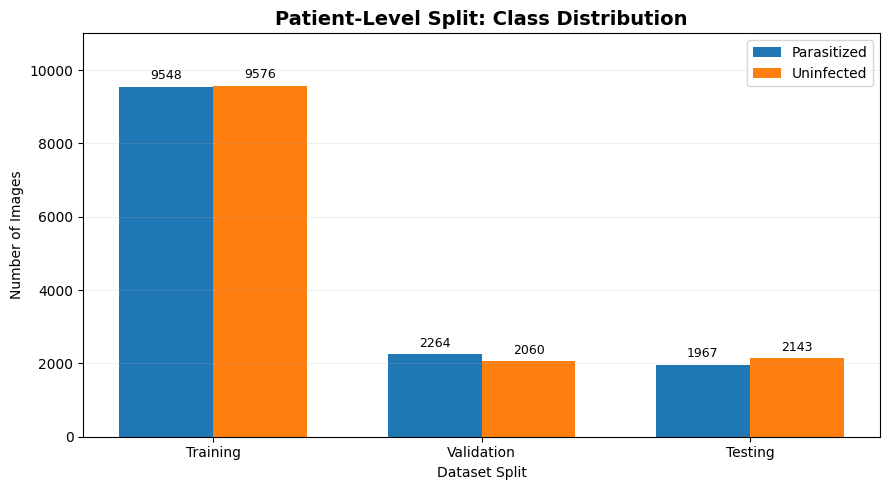

Figure saved successfully!


In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate class distribution
plot_data = pd.crosstab(
    df["split"],
    df["category"]
).reindex(["train", "val", "test"])

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(plot_data))
width = 0.35

bars1 = ax.bar(
    x - width / 2,
    plot_data["Parasitized"],
    width,
    label="Parasitized"
)

bars2 = ax.bar(
    x + width / 2,
    plot_data["Uninfected"],
    width,
    label="Uninfected"
)

# Add values above bars
for bars in [bars1, bars2]:
    ax.bar_label(bars, padding=3, fontsize=9)

ax.set_title(
    "Patient-Level Split: Class Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Dataset Split")
ax.set_ylabel("Number of Images")
ax.set_xticks(x)
ax.set_xticklabels(["Training", "Validation", "Testing"])
ax.legend()

ax.set_ylim(0, 11000)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save the figure
figures_dir = PROJECT_ROOT / "figures"
figures_dir.mkdir(exist_ok=True)

plt.savefig(
    figures_dir / "patient_split_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")